# Figure 4 — v1 SimSiam and SwAV hyperparameter screen

The retained configurations are the second screen design on unified dataset v1.



In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "plagnetplus").is_dir())
sys.path.insert(0, str(ROOT / "src"))
OUTPUT = ROOT / "figures" / "final"
OUTPUT.mkdir(parents=True, exist_ok=True)

import pandas as pd
from IPython.display import display
from plagnetplus.figures.grid_search import plot_marginal_response, plot_simsiam_grid, plot_swav_grid

REFERENCE = ROOT / "results/reference/v1_grid_search"
simsiam = pd.read_csv(REFERENCE / "simsiam_metrics.csv")
swav = pd.read_csv(REFERENCE / "swav_metrics.csv")
simsiam_table = simsiam.assign(Method="SimSiam")
swav_table = swav.assign(Method="SwAV")
display(pd.concat([simsiam_table, swav_table], ignore_index=True).set_index(["Method", "trial_id"]))

from IPython.display import Image as IPyImage, Markdown

def show_saved_figure(path):
    path = Path(path)
    display(Markdown(f"**Saved figure:** `{path}`"))
    display(IPyImage(filename=str(path)))


learning_rate  predictor_learning_rate  weight_decay  \
Method  trial_id                                                         
SimSiam s01               0.025                    0.025       0.00001   
        s02               0.025                    0.025       0.00010   
        s03               0.025                    0.050       0.00001   
        s04               0.025                    0.050       0.00010   
        s05               0.050                    0.025       0.00001   
        s06               0.050                    0.025       0.00010   
        s07               0.050                    0.050       0.00001   
        s08               0.050                    0.050       0.00010   
        s09               0.100                    0.025       0.00001   
        s10               0.100                    0.025       0.00010   
        s11               0.100                    0.050       0.00001   
        s12               0.100                    0.050       0.00010   
SwAV    w01               0.150                      NaN           NaN   
        w02               0.300                      NaN           NaN   
        w03               0.600                      NaN           NaN   
        w04               0.150                      NaN           NaN   
        w05               0.300                      NaN           NaN   
        w06               0.600                      NaN           NaN   
        w07               0.150                      NaN           NaN   
        w08               0.300                      NaN           NaN   
        w09               0.600                      NaN           NaN   
        w10               0.150                      NaN           NaN   
        w11               0.300                      NaN           NaN   
        w12               0.600                      NaN           NaN   

                  final_train_loss  final_validation_loss  \
Method  trial_id                                            
SimSiam s01              -0.965648              -0.961464   
        s02              -0.968430              -0.965236   
        s03              -0.962803              -0.959900   
        s04              -0.968148              -0.966796   
        s05              -0.977561              -0.974944   
        s06              -0.981174              -0.979016   
        s07              -0.974820              -0.973082   
        s08              -0.980594              -0.981530   
        s09              -0.987502              -0.988345   
        s10              -0.991409              -0.992751   
        s11              -0.986325              -0.987034   
        s12              -0.990154              -0.991742   
SwAV    w01               5.516141               5.520202   
        w02               5.520233               5.521084   
        w03               5.521122               5.521286   
        w04               1.291757               5.773026   
        w05               1.248717               5.757208   
        w06               1.199584               5.813689   
        w07               6.184351               6.209728   
        w08               6.206407               6.212171   
        w09               6.213712               6.214129   
        w10               1.935217               6.467927   
        w11               1.874874               6.521918   
        w12               1.820673               6.413216   

                  final_train_collapse  final_validation_collapse  \
Method  trial_id                                                    
SimSiam s01                   0.067889                   0.302869   
        s02                   0.068479                   0.303252   
        s03                   0.057761                   0.275106   
        s04                   0.060394                   0.271588   
        s05                   0.084840                   0.315826   
        s06            

**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_04a_simsiam_clustered_grid.png`

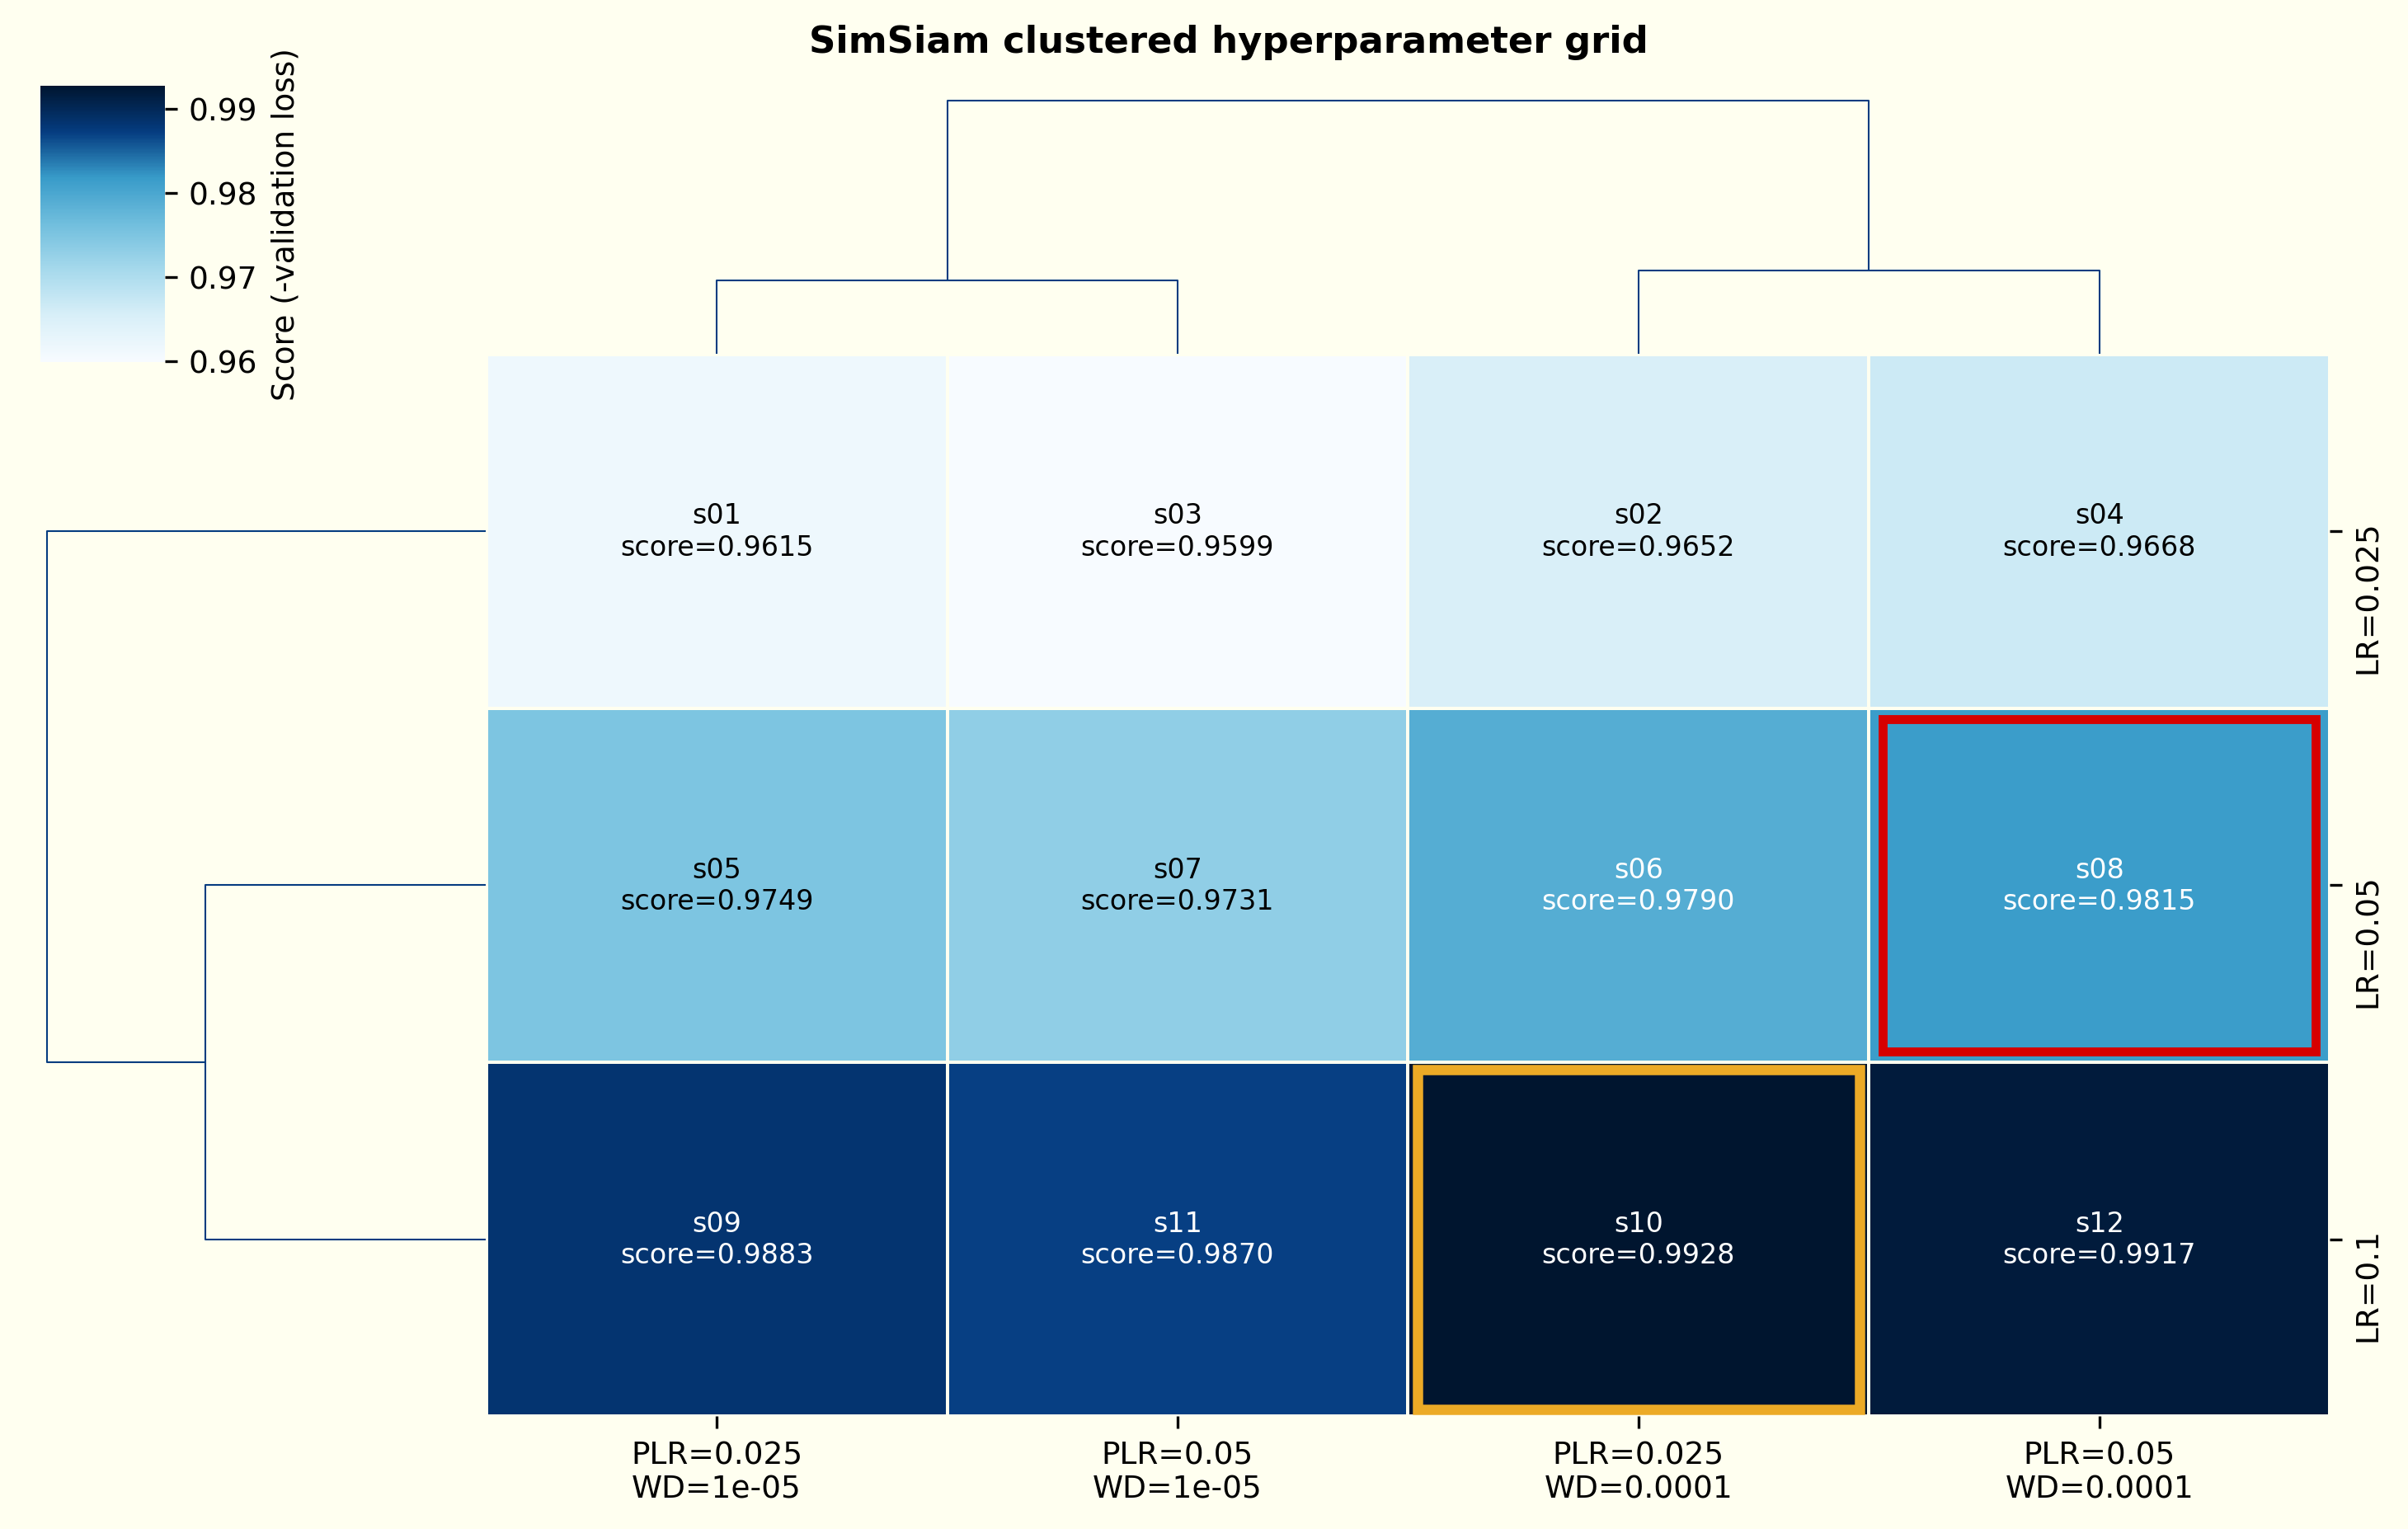

**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_04b_simsiam_marginal_response.png`

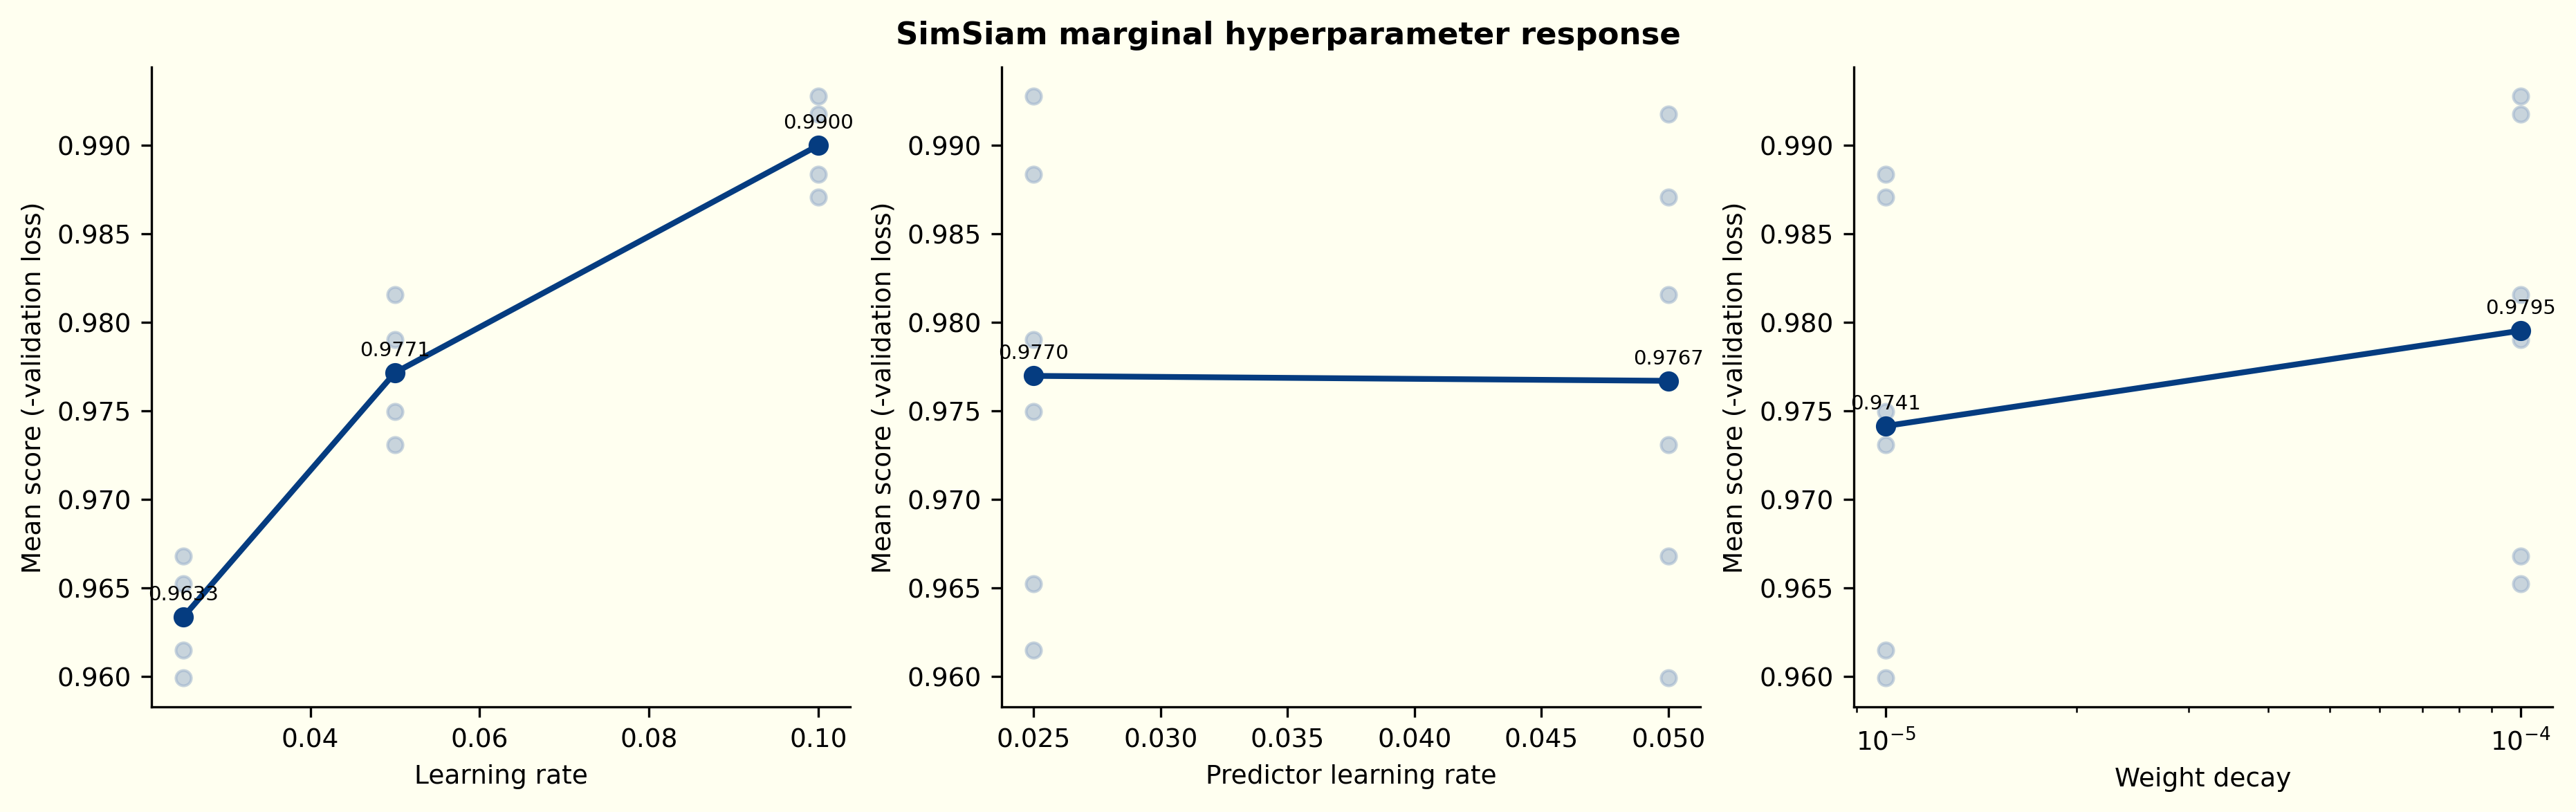

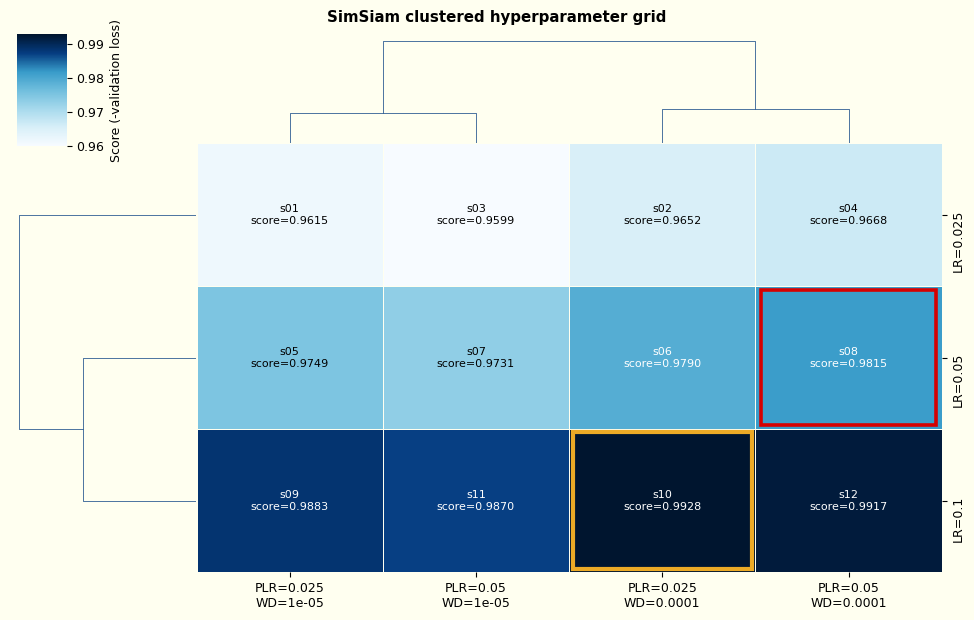

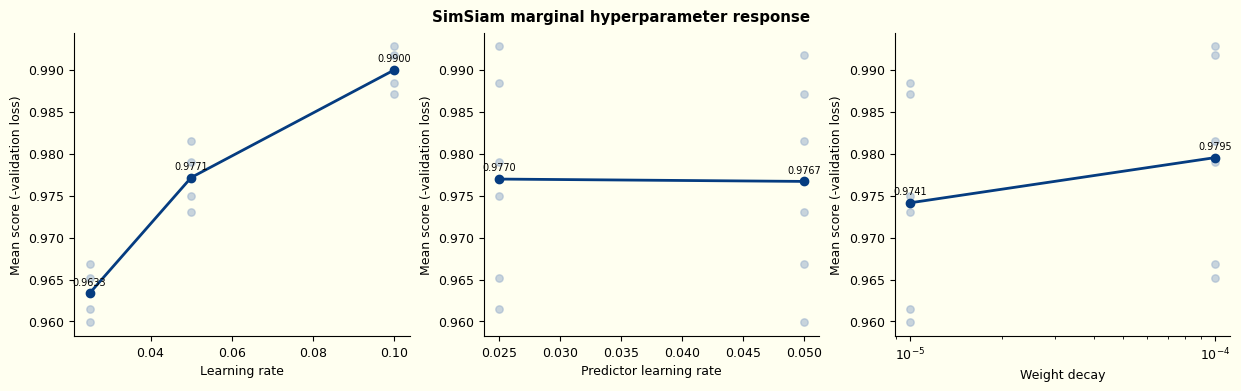

In [2]:
figure = plot_simsiam_grid(simsiam)
out_path = OUTPUT / "figure_04a_simsiam_clustered_grid.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)

simsiam = simsiam.assign(grid_score=-simsiam.final_validation_loss)
figure = plot_marginal_response(
    simsiam,
    score="grid_score",
    parameters=[("learning_rate", "Learning rate"), ("predictor_learning_rate", "Predictor learning rate"), ("weight_decay", "Weight decay")],
    title="SimSiam marginal hyperparameter response",
    ylabel="Mean score (-validation loss)",
)
out_path = OUTPUT / "figure_04b_simsiam_marginal_response.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)


**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_04c_swav_clustered_grid.png`

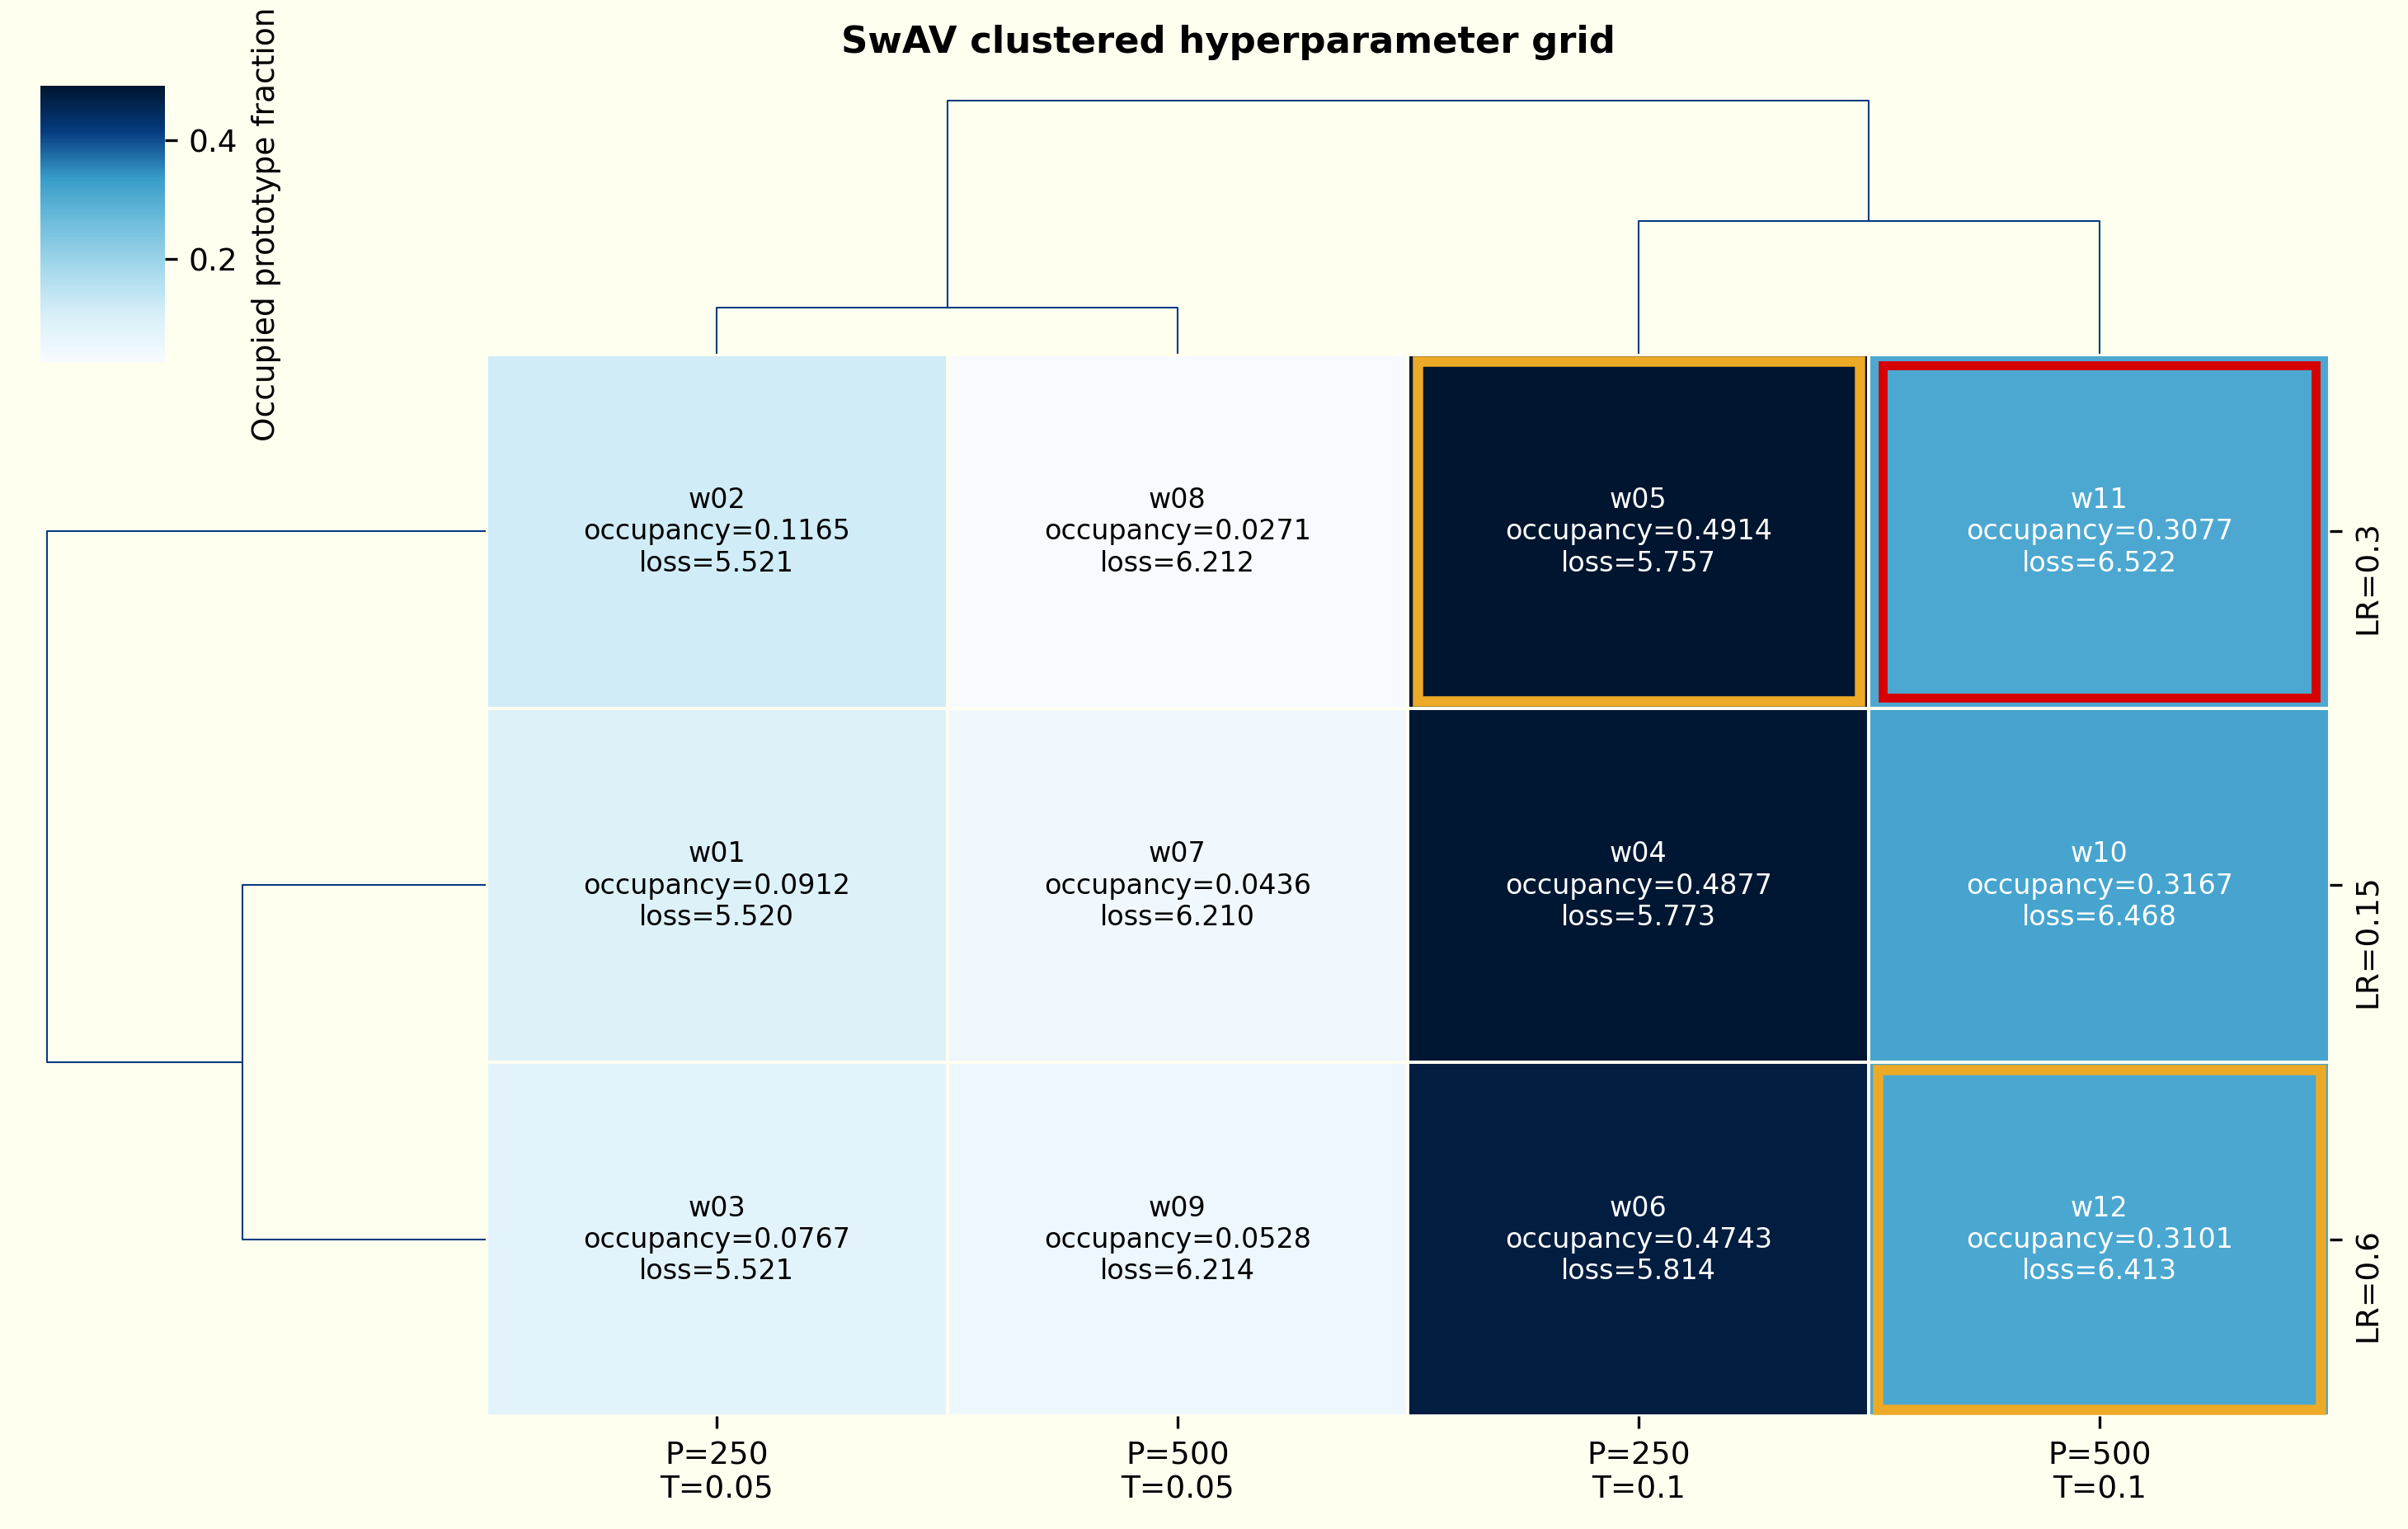

**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_04d_swav_marginal_response.png`

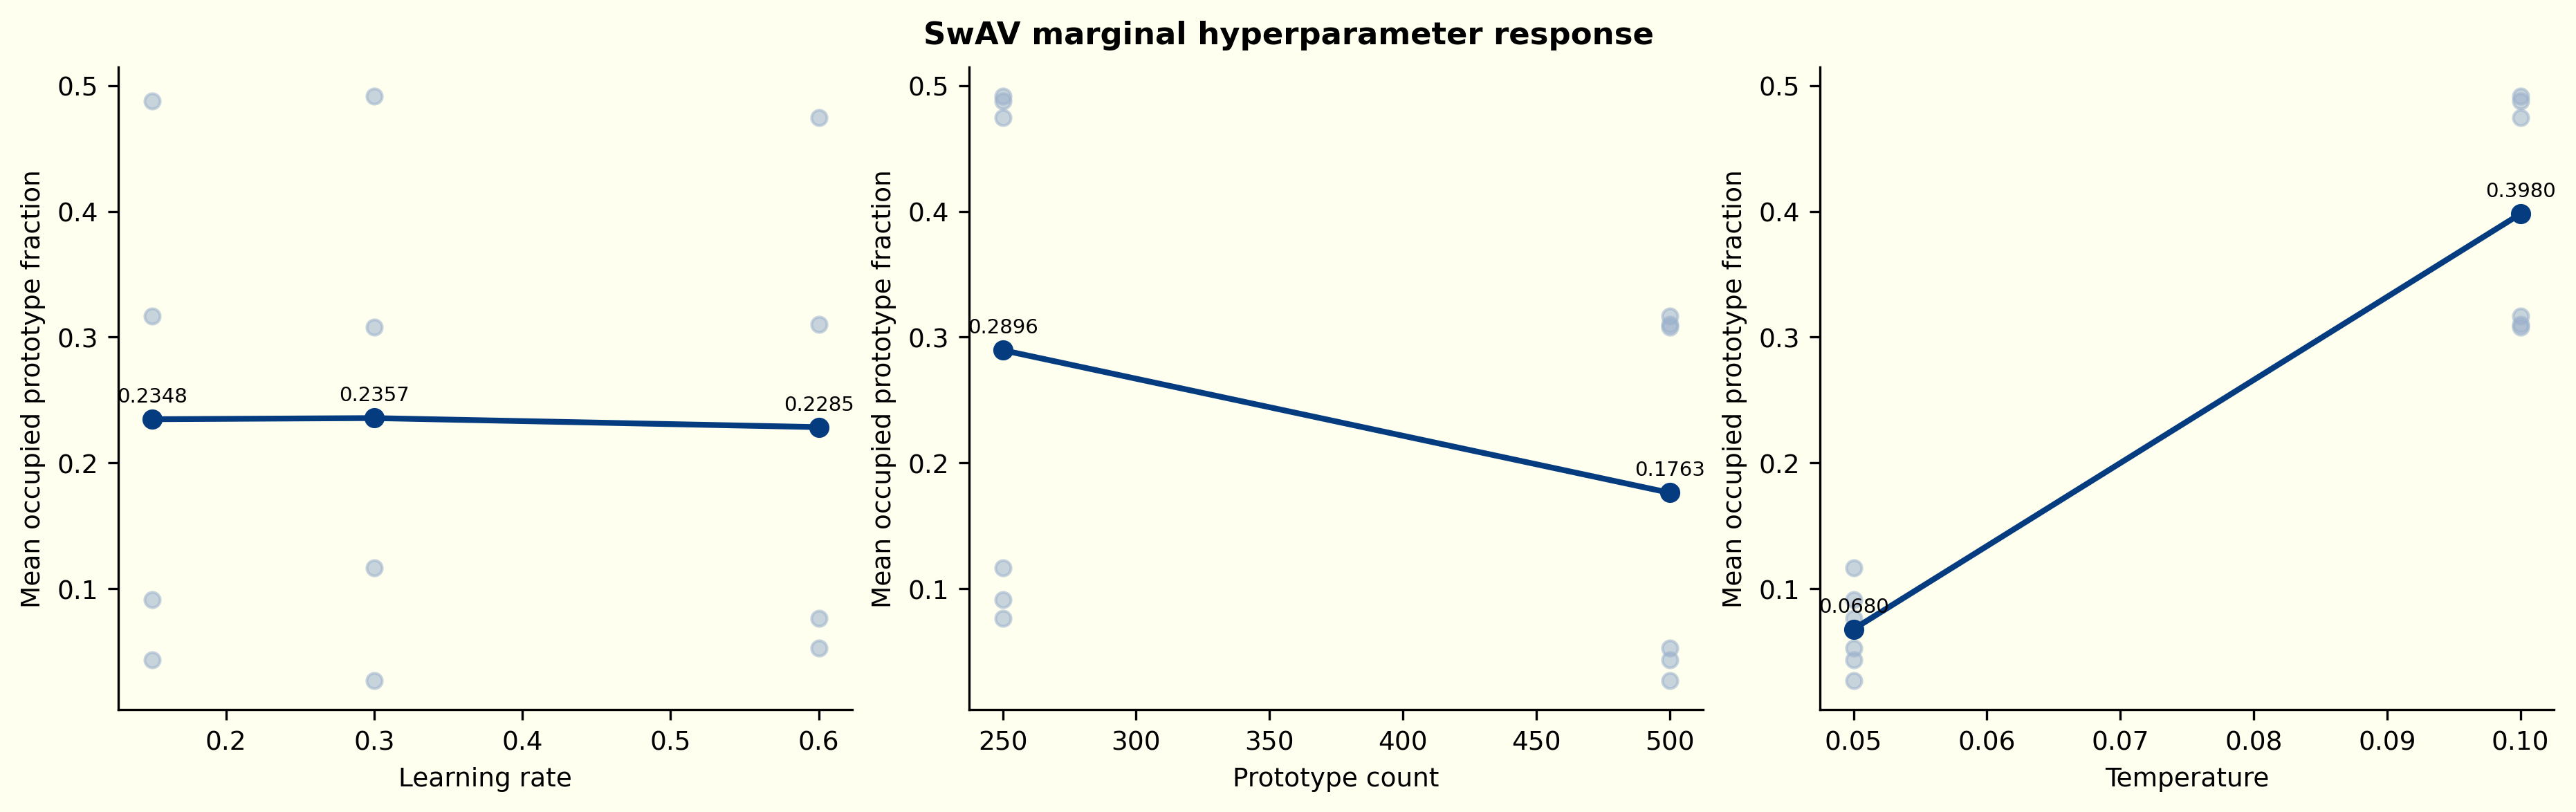

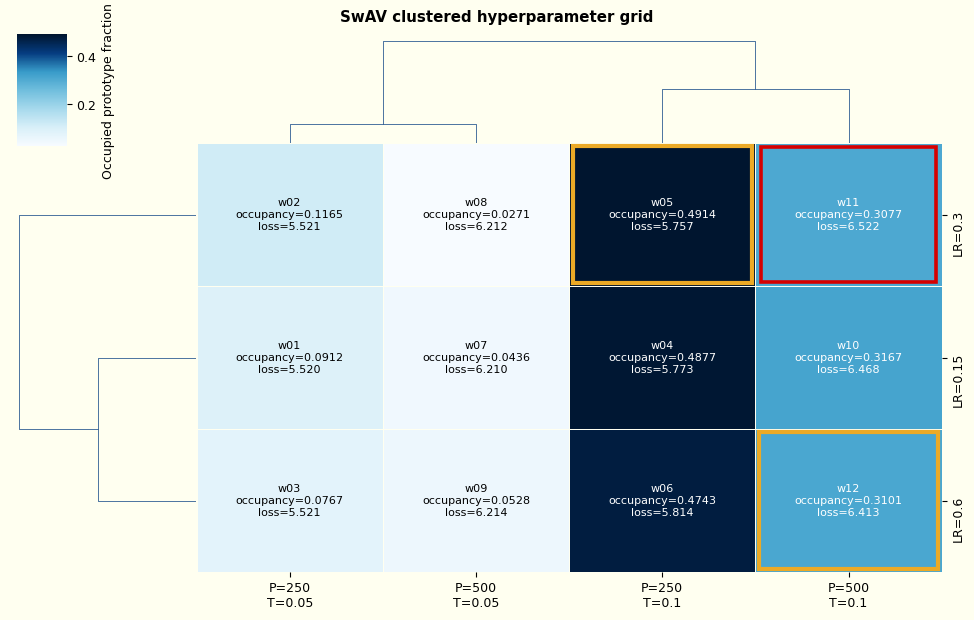

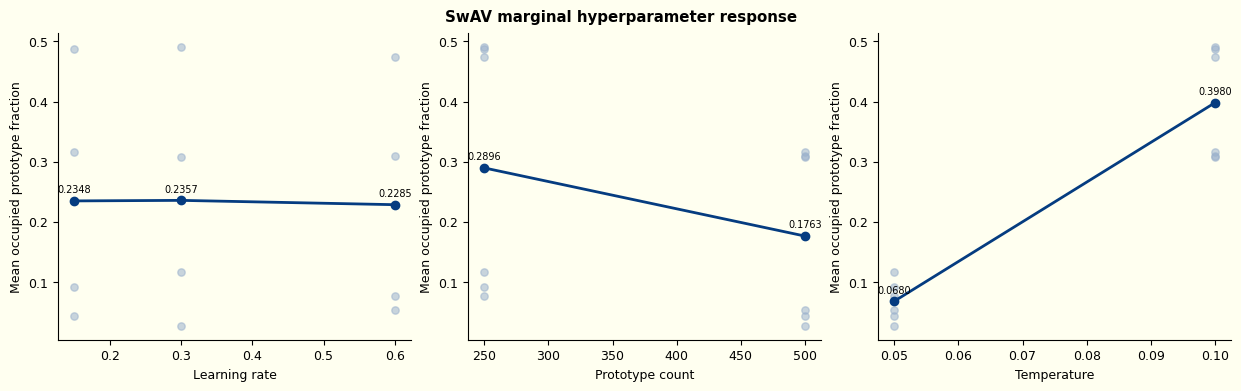

In [3]:
figure = plot_swav_grid(swav)
out_path = OUTPUT / "figure_04c_swav_clustered_grid.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)

figure = plot_marginal_response(
    swav,
    score="occupied_fraction",
    parameters=[("learning_rate", "Learning rate"), ("prototype_count", "Prototype count"), ("temperature", "Temperature")],
    title="SwAV marginal hyperparameter response",
    ylabel="Mean occupied prototype fraction",
)
out_path = OUTPUT / "figure_04d_swav_marginal_response.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)
